# 📏 Lab 05b: Is It Really Better? Statistical Rigor and Judge Calibration for LLM Evals

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/05b-statistical-rigor-judge-calibration-lab.ipynb)

<center><font size="6"><b>"+6 points. The judge says 90%. Ship?"</b></font></center>

<mark>Decide with intervals.</mark> ⏱️ Part 1: ~35 min.

| | |
|---|---|
| ⏱️ **Time** | 70–85 min core, plus optional challenges |
| 🎚️ **Level** | Intermediate. No statistics background needed: each idea is introduced right before you use it |
| 🔑 **Keys needed** | None. Fully offline, seeded simulation. Optional: an OpenAI or Anthropic key for the real-judge section |
| 🧰 **Tools** | `numpy`, `scipy`, `pandas`, `matplotlib` (all preinstalled in Colab) |
| 💻 **You'll code** | Exercises 3A, 6A, 7A, 8A (8A is a short derivation). Each has a safe fallback, so *Run All* always works |
| 🎛️ **You'll play with** | A p-hacking slot machine that manufactures fake wins on demand, and a judge-quality slider |
| 🏁 **You'll leave with** | A SHIP / BLOCK call backed by confidence intervals, a sample-size plan, a calibrated judge, and a reusable eval report card |

**How this lab works**
- ▶️ **Run**: <kbd>Shift</kbd>+<kbd>Enter</kbd>; 🧰 cells just need running.
- ✋ **Your turn**: fill the `...`; auto-graded.
- ❓ **Quick check**: pick, then run.
- 🔑 **Key takeaway**: the line to remember.

<!-- img: noise-sources.png -->
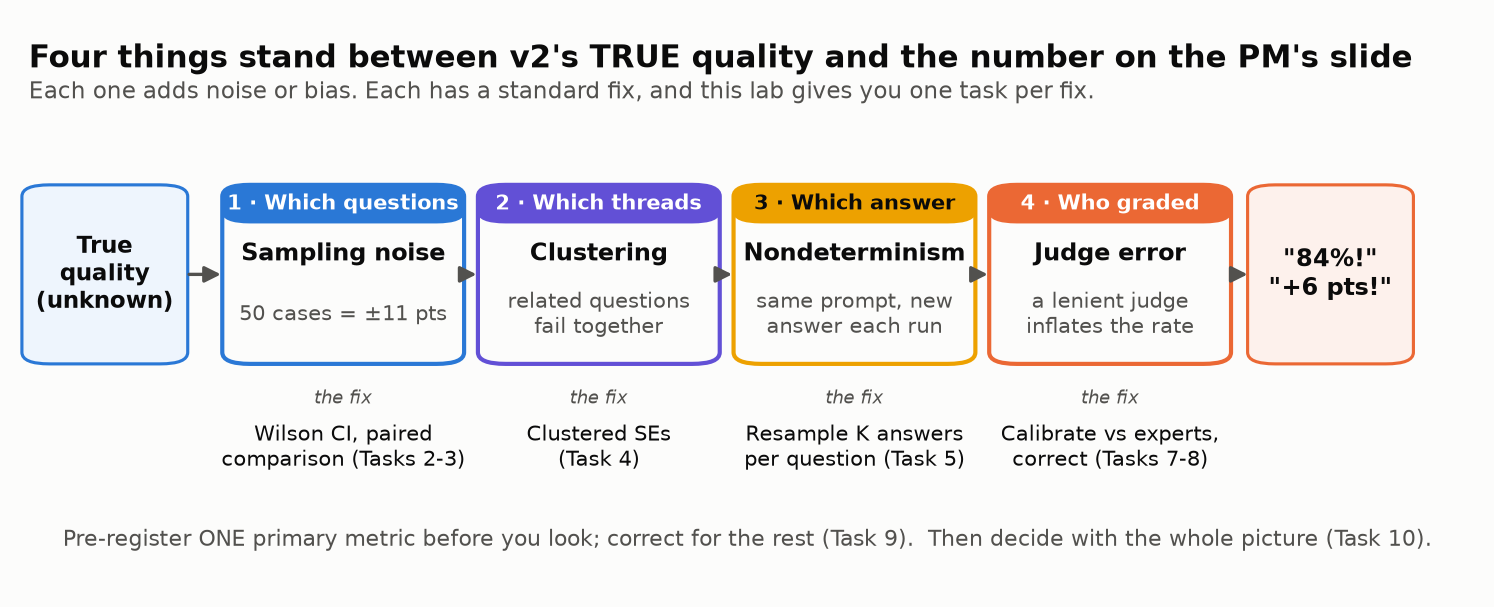

<details><summary>🎯 Objectives · setup · scenario</summary>

## 🎯 Learning Objectives

Intervals, pairing, clustering, resampling, power; judge calibration and correction; Holm; a report card.

## 📋 Prerequisites

Module 05, `numpy`, `pandas`. No statistics needed.

## ⏱️ Estimated Time

70–85 min (Part 2: Tasks 7–10).

## 🧪 Environment and Setup

Offline, seeded. No installs, no keys.

## 📖 Scenario

**Brightbook** (fictional) tax software: you sign off on prompt v2.
</details>

<details><summary>📖 Jargon decoder: 40 terms this lab uses (click to open)</summary>

| Term | Plain-English meaning | Where you'll meet it |
|---|---|---|
| **Golden set** | A fixed test set of questions with expert-graded answers, re-run on every version | Task 1 |
| **LLM judge** | A language model prompted to grade another model's answer PASS or FAIL | Tasks 1, 7–8 |
| **GA** (general availability) | Releasing to every customer, not a beta slice | Scenario |
| **Enrolled agent** ("the tax pro") | A federally licensed US tax professional; the ground truth in this lab | Scenario |
| **Point estimate** | One number (78%) with no error bar | Task 2 |
| **Standard error (SE)** | The typical size of an estimate's wobble from one sample of questions to the next | Task 2 |
| **Confidence interval (CI)**, **coverage** | A range from a recipe that captures the truth in 95% of repeated samples; that 95% is its coverage | Task 2 |
| **Wilson interval** | A CI for pass rates that stays honest at small n and near 0% or 100% | Task 2 |
| **Null** (null hypothesis) | The "nothing changed" world you test against | Task 2 |
| **p-value** | In the null world, the chance of a result at least this extreme. *Not* the chance the null is true | Task 3 |
| **Two-sided** | Counts extreme results in both directions (better *or* worse) | Task 3 |
| **Paired vs unpaired** | Comparing the same questions one by one vs comparing two separate pass rates | Task 3 |
| **Discordant pairs** (fixed / broke) | Questions whose PASS/FAIL outcome changed between versions | Task 3 |
| **McNemar test** | A coin-flip test on the fixed vs broke split | Tasks 3, 9 |
| **Correlation (r)** | How much two things move together, from −1 to 1; 0 = unrelated | Task 3 |
| **Standard deviation (SD)**, **variance**, `ddof=1` | Spread around the mean; variance = SD²; `ddof=1` divides by n − 1, the usual choice for a sample | Tasks 3, 6 |
| **Cluster**, **clustered SE** | A group of correlated cases (one conversation); an SE that sums within each group first | Task 4 |
| **Effective n** | How many independent cases a correlated set is really worth | Task 4 |
| **Bootstrap**, **with replacement** | Resample your data (repeats allowed), recompute, repeat; the middle 95% of results is the CI | Tasks 4, 8 |
| **Nondeterminism** | Same input, different output on different runs | Task 5 |
| **Resampling K answers** | Asking each question K times and averaging per question | Task 5 |
| **Power**, **α**, **β** | Power = chance of detecting a real change; α = false-alarm rate; β = miss rate = 1 − power | Task 6 |
| **δ**, **MDE** | The smallest change you care about; the smallest change your set can reliably detect | Task 6 |
| **z-cutoff** | Distance from the center of a bell curve in SEs; ±1.96 holds the middle 95% | Task 6 |
| **σ²**, **ω²** | Answer-to-answer randomness within a question; true variation of the gain between questions | Task 6 |
| **Positive class** | The label treated as "yes" (here PASS) | Task 7 |
| **Confusion matrix** (TP, FN, FP, TN) | The 2×2 table of judge vs expert verdicts | Task 7 |
| **TPR**, **TNR** | Share of good answers the judge passes; share of bad answers it catches | Task 7 |
| **Imbalanced labels** | One class dominates (here most answers pass) | Task 7 |
| **Cohen's κ** (kappa) | Agreement beyond what chance alone would produce; 0 = chance, 1 = perfect | Task 7 |
| **Rogan-Gladen correction** | Back-calculates the true pass rate from a judge's rate and its TPR/TNR | Task 8 |
| **Youden's J** | TPR + TNR − 1: the share of any real change that survives the judge | Task 8 |
| **Multiple comparisons**, **family-wise error rate** | Testing many metrics; the chance that at least one is a false alarm | Task 9 |
| **Bonferroni**, **Holm** | Corrections that scale p-values by the number of tests | Task 9 |
| **Pre-registration**, **exploratory** | Naming the primary metric before looking; everything else is a lead, not a win | Task 9 |
| **Non-inferiority** | Testing that v2 is not worse than v1 by more than a set margin | Task 10 |
| **Delta method** | Propagating small input errors through a formula using its derivatives | Challenge 3 |
| **Tax terms in the data** | *1099-NEC*: IRS form reporting payments to an independent contractor. *S-corp / K-1*: a corporation whose income passes through to its owners, each told their share on a Schedule K-1. *Section 179*: deduct equipment in the year you buy it. *Safe harbor*: estimated-tax payment levels that avoid an underpayment penalty. *QBI*: the qualified business income deduction for pass-through owners | Golden set (Task 1), optional judge section |
| **Structured output**, **pydantic** | Forcing a model's reply into a schema; pydantic declares that schema as a Python class | Optional judge section |
| **DROP, MGSM, RACE-H, HealthBench** | Public benchmarks cited in research cards: reading + arithmetic, multilingual grade-school math, exam reading comprehension, medical conversations | Research cards |

</details>


## 🧪 Environment and Setup

▶️ **Run** the next four cells: imports · 🎨 lab kit · 🧰 harness (the simulator) · 🧰 chart helpers.

In [ ]:
# Everything below is preinstalled in Google Colab.
# Running locally? pip install numpy pandas scipy matplotlib
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)
print("✅ Environment ready")

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v2 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
#   check(label, got, expected, hint=, success=) -> grades a ✋ Your turn exercise: ✅ / ❌ + hint / ⏳ (still `...`)
#   quiz(label, choice, correct, why, wrong=)    -> grades a ❓ dropdown answer and explains it
#   todo(x)                                      -> True while an exercise blank is still `...`
#   scoreboard()                                 -> your exercise + quiz score so far, and what to revisit
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


# ----------------------------------------------------------------- interactive: exercises, quizzes, score
_SCORE = {}   # label -> (kind, status) where status is "pass" | "fail" | "todo"


class _Graded(int):
    """check()/quiz() result: works like True/False (if, ==, sum) but prints nothing as a cell's last line."""
    def __repr__(self):
        return "True" if self else "False"

    def _ipython_display_(self):
        pass


def todo(x):
    """True while an exercise blank is still `...` (or None)."""
    return x is Ellipsis or x is None


def _card(icon, label, headline, body, accent, tint):
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:10px 16px;margin:8px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {_md(label)}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:3px 0 4px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def _same(got, expected, tol):
    try:
        import numpy as _np
        if isinstance(got, (_np.generic,)):
            got = got.item()
        if isinstance(expected, (_np.generic,)):
            expected = expected.item()
    except ImportError:
        pass
    if isinstance(expected, bool) or isinstance(got, bool):
        return got == expected
    if isinstance(expected, (int, float)) and isinstance(got, (int, float)):
        return abs(float(got) - float(expected)) <= tol * max(1.0, abs(float(expected)))
    if isinstance(expected, str) and isinstance(got, str):
        return got.strip().lower() == expected.strip().lower()
    if isinstance(expected, (set, frozenset)) or isinstance(got, (set, frozenset)):
        try:
            return set(got) == set(expected)
        except TypeError:
            return False
    return got == expected


def check(label, got, expected=None, *, ok=None, tol=1e-6, hint="", success="", reveal=False):
    """Grade a ✋ Your turn exercise.

    got:      the learner's answer (still `...` = not attempted yet: shows ⏳, never an error)
    expected: the reference answer (compared with tolerance for numbers, case-insensitively for strings)
    ok:       pass a bool instead of `expected` for custom rules (e.g. ok=my_case_fools_the_grader)
    reveal:   show the expected answer on a wrong attempt (default False: the hint teaches, the answer spoils)
    """
    if todo(got):
        _SCORE[label] = ("exercise", "todo")
        _card("⏳", f"Your turn · {label}", "Not attempted yet",
              "Replace the `...` above with your answer and re-run this cell. "
              "The lab keeps going with the reference answer, so later cells still work.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    try:
        passed = bool(ok) if ok is not None else _same(got, expected, tol)
    except Exception:
        passed = False
    _SCORE[label] = ("exercise", "pass" if passed else "fail")
    if passed:
        _card("✅", f"Correct · {label}", success or "Nice. That matches the reference.", "", "#0ca30c", "#ecf8ec")
    else:
        shown = f"You got `{got!r}`" + (f"; expected `{expected!r}`" if reveal and ok is None and expected is not None else "") + "."
        _card("❌", f"Not yet · {label}", shown, (f"💡 Hint: {hint}" if hint else "Re-read the step above and try again."),
              "#d03b3b", "#fcefef")
    return _Graded(passed)


def quiz(label, choice, correct, why, wrong=None):
    """Grade a ❓ dropdown answer. choice: the @param string, e.g. "B) The average hides it".
    correct: the letter ("B"). why: the explanation (shown once answered). wrong: {letter: feedback for that pick}."""
    pick = str(choice).strip()[:1].upper()
    if not pick.isalpha():
        _SCORE[label] = ("quiz", "todo")
        _card("❓", f"Quick check · {label}", "Pick an answer in the dropdown, then run this cell.",
              "Commit before you scroll: a guess you wrote down is what makes the next result stick.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    passed = pick == str(correct).strip()[:1].upper()
    _SCORE[label] = ("quiz", "pass" if passed else "fail")
    extra = (wrong or {}).get(pick, "")
    if passed:
        _card("✅", f"Quick check · {label}", f"Right: {correct}.", why, "#0ca30c", "#ecf8ec")
    else:
        _card("🔁", f"Quick check · {label}", f"Not quite: you picked {pick}, the answer is {correct}.",
              (extra + "\n" if extra else "") + why, "#ec835a", "#fdf1ec")
    return _Graded(passed)


def scoreboard():
    """Your score on every ✋ exercise and ❓ quick check you've run, plus what to revisit."""
    ex = [s for k, s in _SCORE.values() if k == "exercise"]
    qz = [s for k, s in _SCORE.values() if k == "quiz"]
    redo = [lbl for lbl, (_, s) in _SCORE.items() if s != "pass"]
    tiles([
        ("✋ Exercises solved", f"{ex.count('pass')}/{len(ex)}", f"{ex.count('todo')} not attempted",
         "good" if ex and ex.count("pass") == len(ex) else "warning"),
        ("❓ Quick checks right", f"{qz.count('pass')}/{len(qz)}", f"{qz.count('todo')} unanswered",
         "good" if qz and qz.count("pass") == len(qz) else "warning"),
    ])
    if redo:
        insight("Worth a second pass", "\n".join(f"• {r}" for r in redo), kind="warning")
    elif _SCORE:
        insight("Clean sweep", "Every exercise and quick check correct. Try the 🏆 challenges next.", kind="insight")


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), check(), quiz(), scoreboard()")

In [ ]:
# @title 🧰 Lab harness: the Brightbook simulator + reference solutions (run me; code is hidden)
# ============================================================
# 🧰 LAB HARNESS — the "infrastructure" for this lab
# ============================================================
# This cell builds everything you'll USE but don't need to write:
#   1. golden       — the 50-case golden set the PM used (expert-graded v1 and v2 answers)
#   2. rerun_golden — re-ask the same 50 questions k more times (answers are random!)
#   3. draw_golden_sets — build many *new* 50-case golden sets from the same traffic
#   4. calib / prod — expert-vs-judge labels, and 2,000 judge-graded production answers
#   5. dashboard    — the PM's 10-metric scorecard
#   6. Helpers: bootstrap_corrected, simulate_null_dashboards, use_or_fallback, pct
#   7. Reference solutions (names start with _reference_) used as safety nets.
#      Peeking is allowed if you're stuck, but try the exercise first!
# Everything is simulated from fixed seeds, so the whole class sees the same numbers.
# Because it is a simulation, we also know the TRUTH (hidden in _TRUTH until Task 10).
# ============================================================
import math
import numpy as np
import pandas as pd
from scipy import stats

def _sig(x):
    return 1.0 / (1.0 + np.exp(-x))

# ---- 0. The latent world: each question has a difficulty; questions in one conversation share it ----
_SU, _SE, _SG = 1.3, 0.8, 0.5           # conversation effect, question effect, v2-vs-v1 per-question effect (logit SDs)
_A, _B, _B_NULL = 1.8517534857123885, 0.21638325191438196, 0.045578400982189834   # calibrated: v1 79%, v2 81% (null: v2 = v1)

def _latent(rng, n_conv, q=5):
    d = np.repeat(rng.normal(0, _SU, n_conv), q) + rng.normal(0, _SE, n_conv * q)
    g = rng.normal(0, _SG, n_conv * q)
    return d, g

# ---- 1. The golden set: 10 (anonymized) customer conversations x 5 follow-up questions -----------------
_CONVS = [
    ("C01", "Consulting S-corp, owner lives in NJ, works in NY", ["Do I file in both states?", "Is my NY income taxed twice?", "Which state gets my S-corp K-1 income?", "Do I need a NY nonresident return?", "Can I claim a credit for NY tax on my NJ return?"]),
    ("C02", "Freelance UX designer paid on 1099-NEC", ["Do I owe self-employment tax?", "Can I deduct my laptop?", "What is the 1099-NEC threshold?", "Can I deduct health insurance premiums?", "Should I pay quarterly estimates?"]),
    ("C03", "Rideshare + delivery driver, one car", ["Standard mileage or actual expenses?", "Can I switch methods this year?", "Are commuting miles deductible?", "Do tolls count on top of mileage?", "What records do I need for mileage?"]),
    ("C04", "Etsy candle shop selling in 30 states", ["Do I collect sales tax myself?", "What is a marketplace facilitator?", "Do I need a resale certificate for wax?", "Is shipping taxable?", "Do I file sales tax returns at all?"]),
    ("C05", "Food-truck LLC, single member", ["When are quarterly estimates due?", "How much should I pay each quarter?", "What is the safe-harbor rule?", "Is there a penalty for underpaying?", "Does my LLC file its own return?"]),
    ("C06", "Landscaping company hiring its first W-2 employee", ["What forms does a new hire fill out?", "How often do I deposit payroll taxes?", "What is FUTA?", "Do I need workers' comp?", "Contractor or employee for seasonal help?"]),
    ("C07", "Bakery that bought a $48k oven", ["Can I expense the oven this year?", "Section 179 or bonus depreciation?", "What if I sell the oven in 2 years?", "Does financing change the deduction?", "Is installation part of the cost basis?"]),
    ("C08", "Wedding photographer, side business", ["Is this a business or a hobby?", "Can I deduct a loss against my W-2 income?", "Can I deduct my camera gear?", "Do I need an EIN?", "Is my studio rent deductible?"]),
    ("C09", "Bookkeeping firm with 12 contractors", ["When are 1099-NECs due?", "Do I file 1099s electronically?", "Do I need W-9s on file?", "What if a contractor won't give a TIN?", "Are corporations exempt from 1099s?"]),
    ("C10", "Real-estate agent working from home", ["Can I take the home-office deduction?", "Simplified or regular method?", "Do I qualify for the QBI deduction?", "Is my car a business expense?", "Can I deduct MLS dues?"]),
]
_GOLD_P_V1 = [0.706, 0.31, 0.352, 0.535, 0.429, 0.841, 0.946, 0.961, 0.978, 0.855, 0.874, 0.669, 0.82, 0.906, 0.561,
              0.891, 0.908, 0.962, 0.967, 0.929, 0.974, 0.901, 0.891, 0.943, 0.937, 0.878, 0.905, 0.901, 0.914, 0.921,
              0.427, 0.668, 0.321, 0.585, 0.694, 0.888, 0.937, 0.922, 0.966, 0.936, 0.996, 0.946, 0.997, 0.991, 0.99,
              0.872, 0.915, 0.917, 0.934, 0.916]
_GOLD_P_V2 = [0.753, 0.264, 0.396, 0.593, 0.544, 0.76, 0.972, 0.933, 0.982, 0.867, 0.896, 0.716, 0.817, 0.837, 0.623,
              0.924, 0.96, 0.948, 0.986, 0.905, 0.983, 0.9, 0.933, 0.973, 0.947, 0.749, 0.953, 0.811, 0.923, 0.948,
              0.521, 0.739, 0.273, 0.621, 0.523, 0.908, 0.972, 0.943, 0.919, 0.949, 0.996, 0.96, 0.998, 0.988, 0.99,
              0.869, 0.823, 0.937, 0.959, 0.883]
_GOLD_V1 = "10000111100001111111111111111101001111111111111111"
_GOLD_V2 = "00010111111111111111111111111101000111111111111111"

golden = pd.DataFrame(
    [{"case_id": f"G-{5 * ci + qi + 1:02d}", "conversation": cid, "customer": who, "question": qs[qi]}
     for ci, (cid, who, qs) in enumerate(_CONVS) for qi in range(5)]
)
golden["v1_pass"] = [int(c) for c in _GOLD_V1]
golden["v2_pass"] = [int(c) for c in _GOLD_V2]
_P1, _P2 = np.array(_GOLD_P_V1), np.array(_GOLD_P_V2)


def rerun_golden(version, k=10, seed=0):
    """Re-ask the SAME 50 golden questions k more times with the SAME prompt + model, and have the
    tax pro grade each answer. Returns a (k, 50) array of 0/1. Answers vary run to run (nondeterminism)."""
    p = _P1 if version == "v1" else _P2
    rng = np.random.default_rng([505, seed, 1 if version == "v1" else 2])
    return (rng.random((k, len(p))) < p).astype(int)


def draw_golden_sets(n_sets=5000, null=True, seed=7):
    """Build n_sets brand-new 50-case golden sets (10 conversations x 5 questions) from the same traffic,
    answer each question once with v1 and once with v2, and return the observed pass rates.
    null=True simulates a world where v2 is EXACTLY as good as v1 on average."""
    rng = np.random.default_rng([505, seed])
    d, g = _latent(rng, 10 * n_sets)
    d, g = d.reshape(n_sets, 50), g.reshape(n_sets, 50)
    p1 = _sig(_A - d)
    p2 = _sig(_A - d + (_B_NULL if null else _B) + g)
    o1 = rng.random(p1.shape) < p1
    o2 = rng.random(p2.shape) < p2
    return pd.DataFrame({"v1_rate": o1.mean(1), "v2_rate": o2.mean(1)})


# ---- 2. Production traffic: 2,000 questions (400 conversations) answered by v2 -------------------
_rng = np.random.default_rng([505, 2022])
_d, _g = _latent(_rng, 400)
_PROD_P1, _PROD_P2 = _sig(_A - _d), _sig(_A - _d + _B + _g)
_prod_true = (_rng.random(2000) < _PROD_P2).astype(int)        # what a tax pro WOULD say (unknown in real life)
_JUDGE_TPR, _JUDGE_TNR = 0.97, 0.36                            # the judge's true behavior (unknown in real life)
_u = _rng.random(2000)
_prod_judge = np.where(_prod_true == 1, _u < _JUDGE_TPR, _u >= _JUDGE_TNR).astype(int)

prod = pd.DataFrame({"question_id": [f"P-{i + 1:04d}" for i in range(2000)],
                     "conversation": [f"PC{i // 5 + 1:03d}" for i in range(2000)],
                     "judge_pass": _prod_judge})

# A tax pro (an enrolled agent) labeled a random 200 of those answers; a 2nd pro double-labeled 60.
_cal_idx = np.arange(0, 2000, 10)
calib = pd.DataFrame({"question_id": prod["question_id"].values[_cal_idx],
                      "expert_pass": _prod_true[_cal_idx],
                      "judge_pass": _prod_judge[_cal_idx]})
_u2 = _rng.random(60)
_e1 = calib["expert_pass"].values[:60]
_e2 = np.where(_e1 == 1, _u2 >= 0.04, _u2 < 0.22).astype(int)
calib["expert2_pass"] = pd.array([*_e2, *([pd.NA] * 140)], dtype="Int64")

# ---- 3. The PM's 10-metric dashboard on the golden set (counts of discordant pairs) --------------
_rng_m = np.random.default_rng([505, 270])
_METRICS = ["correct (expert)", "cites the right IRS form", "asks for missing facts", "escalates when required",
            "plain language", "no SSN/EIN echoed back", "states the deadline", "includes disclaimer",
            "under 200 words", "friendly tone"]
_rows = [{"metric": _METRICS[0], "v1_pass": int(golden.v1_pass.sum()), "v2_pass": int(golden.v2_pass.sum()),
          "v2_fixed": int(((golden.v1_pass == 0) & (golden.v2_pass == 1)).sum()),
          "v2_broke": int(((golden.v1_pass == 1) & (golden.v2_pass == 0)).sum())}]
for m in _METRICS[1:]:
    base = _rng_m.uniform(0.6, 0.92)
    q = _sig(np.log(base / (1 - base)) + _rng_m.normal(0, 1.0, 50))
    a1, a2 = _rng_m.random(50) < q, _rng_m.random(50) < q          # SAME true rate for v1 and v2 (no real effect)
    _rows.append({"metric": m, "v1_pass": int(a1.sum()), "v2_pass": int(a2.sum()),
                  "v2_fixed": int((~a1 & a2).sum()), "v2_broke": int((a1 & ~a2).sum())})
dashboard = pd.DataFrame(_rows)

_TRUTH = {"v1_prod": float(_PROD_P1.mean()), "v2_prod": float(_PROD_P2.mean()),
          "judge_tpr": _JUDGE_TPR, "judge_tnr": _JUDGE_TNR,
          "v2_prod_sampled": float(_prod_true.mean())}


# ---- 4. Reference solutions (the safety nets) --------------------------------------------------
def _reference_paired_diff_ci(v1, v2, z=1.96):
    d = np.asarray(v2, float) - np.asarray(v1, float)
    se = d.std(ddof=1) / math.sqrt(len(d))
    return {"diff": d.mean(), "se": se, "lo": d.mean() - z * se, "hi": d.mean() + z * se}


def _reference_cases_needed(delta, var_per_question, alpha=0.05, power=0.80):
    z_a = stats.norm.ppf(1 - alpha / 2)
    z_b = stats.norm.ppf(power)
    return math.ceil((z_a + z_b) ** 2 * var_per_question / delta ** 2)


def _reference_judge_metrics(expert, judge):
    e, j = np.asarray(expert).astype(int), np.asarray(judge).astype(int)
    tp = int(((e == 1) & (j == 1)).sum()); fn = int(((e == 1) & (j == 0)).sum())
    tn = int(((e == 0) & (j == 0)).sum()); fp = int(((e == 0) & (j == 1)).sum())
    n = len(e)
    agree = (tp + tn) / n
    p_e = ((tp + fn) / n) * ((tp + fp) / n) + ((tn + fp) / n) * ((tn + fn) / n)
    kappa = (agree - p_e) / (1 - p_e) if p_e < 1 else 0.0
    return {"tp": tp, "fn": fn, "tn": tn, "fp": fp, "agreement": agree,
            "tpr": tp / (tp + fn) if tp + fn else float("nan"),
            "tnr": tn / (tn + fp) if tn + fp else float("nan"), "kappa": kappa}


def _reference_rogan_gladen(p_obs, tpr, tnr):
    j = tpr + tnr - 1
    if j <= 0:
        raise ValueError("Judge is no better than chance (TPR + TNR <= 1); correction is undefined.")
    return min(1.0, max(0.0, (p_obs + tnr - 1) / j))


def bootstrap_corrected(calib_expert, calib_judge, prod_judge, correct_fn, B=4000, seed=11):
    """Bootstrap CI for the corrected pass rate. Each round resamples BOTH the expert-labeled
    calibration set (uncertainty in TPR/TNR) and the judged production set (uncertainty in p_obs)."""
    rng = np.random.default_rng([505, seed])
    e, j = np.asarray(calib_expert).astype(int), np.asarray(calib_judge).astype(int)
    pj = np.asarray(prod_judge).astype(int)
    n_c, n_p = len(e), len(pj)
    out = []
    for _ in range(B):
        idx = rng.integers(0, n_c, n_c)
        eb, jb = e[idx], j[idx]
        tpr = jb[eb == 1].mean()
        tnr = 1 - jb[eb == 0].mean()
        p_obs = rng.binomial(n_p, pj.mean()) / n_p
        try:
            out.append(correct_fn(p_obs, tpr, tnr))
        except (ValueError, ZeroDivisionError):
            continue
    out = np.array(out)
    return {"lo": float(np.percentile(out, 2.5)), "hi": float(np.percentile(out, 97.5)), "draws": out}


def simulate_null_dashboards(n_dash=4000, n_metrics=10, alpha=0.05, seed=3):
    """Simulate n_dash dashboards in a world where v2 == v1 on EVERY metric (50 golden cases each).
    Returns the share of dashboards with at least one 'significant' metric, raw vs Holm-corrected."""
    rng = np.random.default_rng([505, seed])
    base = rng.uniform(0.6, 0.92, (n_dash, n_metrics, 1))
    q = _sig(np.log(base / (1 - base)) + rng.normal(0, 1.0, (n_dash, n_metrics, 50)))
    a1, a2 = rng.random(q.shape) < q, rng.random(q.shape) < q
    fixed, broke = (~a1 & a2).sum(-1), (a1 & ~a2).sum(-1)
    n = fixed + broke
    p = np.where(n == 0, 1.0, np.minimum(1.0, 2 * stats.binom.cdf(np.minimum(fixed, broke), np.maximum(n, 1), 0.5)))
    raw_any = (p < alpha).any(1).mean()
    holm_any = (p.min(1) * n_metrics < alpha).mean()        # Holm's first step = Bonferroni on the smallest p
    return {"raw_any": float(raw_any), "holm_any": float(holm_any), "per_test": float((p < alpha).mean())}


def _close(got, want):
    if isinstance(want, dict):
        return isinstance(got, dict) and all(k in got and _close(got[k], want[k]) for k in want)
    return bool(np.isclose(float(got), float(want), rtol=1e-6, atol=1e-9))


def _fmt(x):
    try:
        return f"{float(x):.4g}"
    except (TypeError, ValueError):
        return repr(x)[:60]


def _diff(got, want):
    if isinstance(want, dict):
        if not isinstance(got, dict):
            return f"expected a dict with keys {list(want)}, got {type(got).__name__}"
        for k in want:
            if k not in got:
                return f"missing key '{k}'"
            if not _close(got[k], want[k]):
                return f"'{k}' should be {_fmt(want[k])}, got {_fmt(got[k])}"
    return f"expected {_fmt(want)}, got {_fmt(got)}"


def use_or_fallback(label, yours, reference, cases):
    """Safety net for the 🧠 exercises: test YOUR function against the reference on a few cases.
    If it isn't finished (or disagrees), keep going with the reference so Run All still works."""
    try:
        for i, args in enumerate(cases, start=1):
            got, want = yours(*args), reference(*args)
            if not _close(got, want):
                raise AssertionError(f"test case {i}: {_diff(got, want)}")
        print(f"✅ Exercise {label}: your function matches the reference on {len(cases)} test cases. Using YOUR version.")
        return yours
    except NotImplementedError:
        print(f"📝 Exercise {label} is not done yet, so the reference solution is used and Run All keeps working.")
    except Exception as e:  # noqa: BLE001  (show any learner error, then fall back)
        print(f"❌ Exercise {label}: {type(e).__name__}: {e}\n   → Using the reference solution for now. Fix yours and re-run this cell.")
    return reference


def pct(x, digits=0):
    return f"{100 * x:.{digits}f}%"


print(f"🧰 Harness loaded: golden set ({len(golden)} cases, {golden.conversation.nunique()} conversations), "
      f"calibration set ({len(calib)} expert labels), production run ({len(prod):,} judged answers), "
      f"{len(dashboard)}-metric dashboard.")

In [ ]:
# @title 🧰 Chart helpers for Tasks 2–6 (hidden · 87 lines · expand if curious)
def plot_null_gaps(null_gap, gain, title):
    """Histogram of v2 − v1 across simulated golden sets; gaps at least as big as `gain` drawn in orange."""
    fig, ax = plt.subplots(figsize=(8.5, 3.6))
    bins = np.arange(-0.31, 0.32, 0.02)
    ax.hist(null_gap, bins=bins, color=PALETTE[0], alpha=0.85, edgecolor="#fcfcfb", label="v2 no better")
    ax.hist(null_gap[null_gap >= round(gain, 2)], bins=bins, color=PALETTE[1], edgecolor="#fcfcfb",
            label=f"looks like a ≥{100 * gain:.0f}-pt win")
    ax.axvline(gain, color="#0b0b0b", lw=1.2, ls="--")
    ax.annotate(f"PM's +{100 * gain:.0f} pts", (gain, ax.get_ylim()[1] * 0.92), xytext=(6, 0),
                textcoords="offset points", fontsize=10, color="#0b0b0b")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{100 * x:+.0f}" if abs(x) > 1e-9 else "0"))
    ax.set_axisbelow(True)
    ax.set_xlabel("v2 − v1 on a freshly built 50-case golden set (points)")
    ax.set_ylabel("golden sets (of 5,000)")
    ax.set_title(title)
    ax.legend(loc="upper left")
    plt.show()


def plot_gain_cis(rows, title):
    """One dot + 95% CI bar per row (label, {"diff", "lo", "hi"}, color), in points, with a dashed line at zero."""
    fig, ax = plt.subplots(figsize=(8.5, 2.6))
    for y, (label, res, color) in enumerate(rows):
        ax.plot([100 * res["lo"], 100 * res["hi"]], [y, y], color=color, lw=3, solid_capstyle="round")
        ax.plot(100 * res["diff"], y, "o", color=color, markersize=9, markeredgecolor="#fcfcfb", markeredgewidth=2)
        ax.annotate(f"{100 * res['lo']:+.1f} to {100 * res['hi']:+.1f} pts", (100 * res["hi"], y), xytext=(8, -4),
                    textcoords="offset points", fontsize=10, color="#52514e")
    ax.axvline(0, color="#0b0b0b", lw=1, ls="--")
    ax.set_yticks(range(len(rows)), [r[0] for r in rows])
    ax.set_ylim(-0.6, len(rows) - 0.4)
    ax.set_xlim(-15, 32)
    ax.set_xlabel("v2 − v1 (points), dot = estimate, bar = 95% CI")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    plt.show()


def plot_net_by_conversation(by_conv, title):
    """One bar per conversation: net questions v2 fixed minus broke (green up, orange down, gray zero)."""
    fig, ax = plt.subplots(figsize=(8.5, 3.4))
    colors = [PALETTE[2] if v > 0 else PALETTE[1] if v < 0 else "#b9b8b3" for v in by_conv.net_change]
    ax.bar(by_conv.conversation, by_conv.net_change, color=colors, width=0.6)
    ax.axhline(0, color="#0b0b0b", lw=0.8)
    ax.set_axisbelow(True)
    for i, v in enumerate(by_conv.net_change):
        if v:
            ax.annotate(f"{v:+d}", (i, v), xytext=(0, 4 if v > 0 else -14), textcoords="offset points",
                        ha="center", fontsize=10, color="#0b0b0b")
    ax.set_ylabel("net questions (fixed − broke)")
    ax.set_ylim(-1.8, by_conv.net_change.max() + 1)
    ax.set_title(title)
    plt.show()


def plot_reruns(runs, golden_run, title):
    """One row of dots per version (its K re-run pass rates) plus a hollow diamond at its golden-set run."""
    K = len(runs)
    fig, ax = plt.subplots(figsize=(8.5, 2.8))
    for y, (name, color) in enumerate([("v1", PALETTE[0]), ("v2", PALETTE[1])]):
        ax.scatter(100 * runs[name], [y] * K, s=70, color=color, alpha=0.75, edgecolor="#fcfcfb", linewidth=1.5,
                   label=f"{name}: {K} re-runs")
        ax.scatter(100 * golden_run[name], y, s=110, marker="D", facecolor="none", edgecolor="#0b0b0b", linewidth=1.5,
                   label="golden-set run" if y else None)
    ax.set_yticks([0, 1], ["v1", "v2"])
    ax.set_ylim(-0.7, 1.7)
    ax.set_xlabel("pass rate on the same 50 questions (%)")
    ax.set_title(title)
    ax.legend(loc="upper left", ncol=3, fontsize=9)
    ax.grid(axis="y", visible=False)
    plt.show()


def plot_power_curves(designs, n_have, title):
    """Questions needed (log scale) vs the smallest true change to detect: one curve per design."""
    fig, ax = plt.subplots(figsize=(8.5, 3.8))
    deltas = np.linspace(0.02, 0.20, 60)
    for (name, v), color in zip(designs.items(), [PALETTE[6], PALETTE[0], PALETTE[2]]):
        ax.plot(100 * deltas, [cases_needed(dl, v) for dl in deltas], color=color, label=name)
    ax.axhline(n_have, color="#0b0b0b", lw=1, ls="--")
    ax.annotate(f"your golden set: {n_have} questions", (2, n_have), xytext=(0, -14), textcoords="offset points",
                fontsize=10)
    ax.set_yscale("log")
    ax.set_xlabel("smallest true change you want to detect (points)")
    ax.set_ylabel("questions needed (log scale)")
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=9)
    plt.show()

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

**Checkpoint ✅** `✅ Environment ready`, `🎨 Lab kit loaded…`, `🧰 Harness loaded: golden set (50 cases, 10 conversations)…`
</details>

---

🧭 **Where you are:** Part 1 · Is the +6 real? (Tasks 1–6)

## Task 1: The PM's Claim

<big><b>This call is the last check before v2 answers every customer in filing season.</b></big>

> 🎯 **Goal:** see the PM's evidence and commit to a call before any analysis.<br>
> ❓ **The question:** how much evidence is "+6 points"?<br>
> 👀 **Watch for:** what one question is worth on 50 cases.

> 💬 **Priya (PM):** v2 lifts our 50-case golden set from **78% to 84%**, and the judge says production is **90%**. Ship Monday? 🚀

**Policy:** a tax pro grades PASS/FAIL; GA needs **≥ 85%** in production; a gain needs a 95% CI above zero.

<!-- img: launch-two-questions.png -->
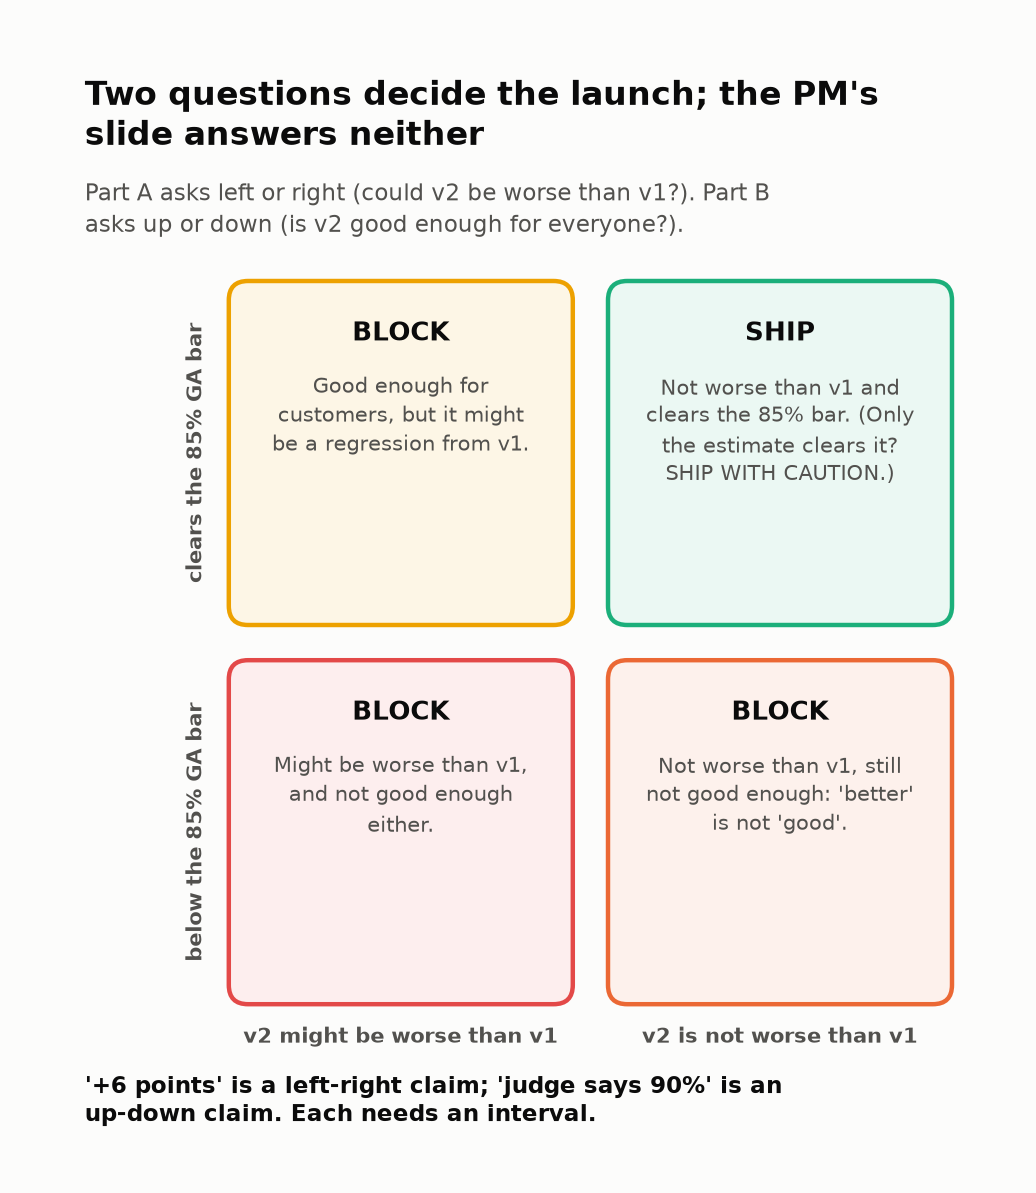

<sub>🖼️ *Ships only from the top-right; neither headline comes with an interval.*</sub>

▶️ **Run:** the PM's evidence → read the four tiles.

In [ ]:
LAUNCH_BAR = 0.85                     # Brightbook GA policy: >= 85% expert-graded correctness

n = len(golden)
k1, k2 = int(golden.v1_pass.sum()), int(golden.v2_pass.sum())
r1, r2 = k1 / n, k2 / n
gain = r2 - r1
judge_rate = prod.judge_pass.mean()

display(golden.head(6))
tiles([
    ("v1 pass rate (golden set)", pct(r1), f"{k1} of {n} questions", None),
    ("v2 pass rate (golden set)", pct(r2), f"{k2} of {n} questions", None),
    ("Claimed gain", f"+{100 * gain:.0f} pts", "the PM's headline", "warning"),
    ("Judge says (production)", pct(judge_rate, 1), f"GA bar is {pct(LAUNCH_BAR)}",
     "good" if judge_rate >= LAUNCH_BAR else "critical"),
])

✋ **Your turn:** translate the headline back into test cases.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_net = round(gain * n)

In [ ]:
# ✋ Your turn: the PM's headline is +6 points on a 50-question golden set.
#    How many questions is that, net (v2 passes minus v1 passes)?
my_net_questions = ...   # ✏️ one expression using gain and n

check("Translate +6 points into questions", my_net_questions, _ref_net,
      hint="On n questions, each question is worth 1/n of the pass rate. Multiply the gain by n.",
      success=f"{_ref_net} questions: on {n} cases each one is worth {100 / n:.0f} points. Every headline in this lab shrinks once you count the cases.")

✍️ **Your call** (double-click to edit): SHIP, SHIP WITH CAUTION or BLOCK, and how sure (0–100%)? Revisit it in Task 10.

*My call: … · confidence: …%*

In [ ]:
# @title ❓ Quick check: v2 passed 42 golden questions and v1 passed 39. What can you conclude yet?
answer = "— pick one —"  # @param ["— pick one —", "A) Three more questions passed; nothing yet says whether that is signal or chance", "B) v2 is 6 points better", "C) v2 is 7.7% better in relative terms, so even more than 6", "D) v2 clears the GA bar, so the gain does not matter"]
quiz('What +6 means', answer, correct="A",
     why='Three questions out of 50 is small. Task 2 measures how often chance alone produces it.',
     wrong={"B": 'That is the headline restated. Whether 3 questions is a signal is the open question.',
          "C": 'Relative or absolute, it is still 3 questions.',
          "D": 'The bar applies to production, graded by a judge nobody has validated yet (Part 2).'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Translate every headline back into how many test cases changed.</b></font>

</td></tr></table>

---

## Task 2: How Noisy Is a 50-Case Score?

<big><b>A pass rate without an interval invites a launch decision on noise.</b></big>

> 🎯 **Goal:** put an error bar on each pass rate, then count chance-made 6-point "wins".<br>
> ❓ **The question:** if v2 changed nothing, how often would it still look 6 points better?<br>
> 👀 **Watch for:** the orange tail of the histogram.

> 📘 **Concept · Confidence interval (Wilson)**
>
> **What it is:** a range built by a recipe that, across many golden sets, contains the true pass rate 95% of the time (its **coverage**). Wilson's recipe stays inside 0–100% and keeps that promise at small *n*.
>
> **What it can't tell you:** whether the grader is right. It covers *which questions you happened to draw*; a biased judge (Part B) sits outside it.
>
> **Anchor:** v1's 39 of 50 is "78%, 95% CI 65% to 87%", and a perfect 50 of 50 is still only "93% to 100%".

<!-- img: ci-coverage.png -->
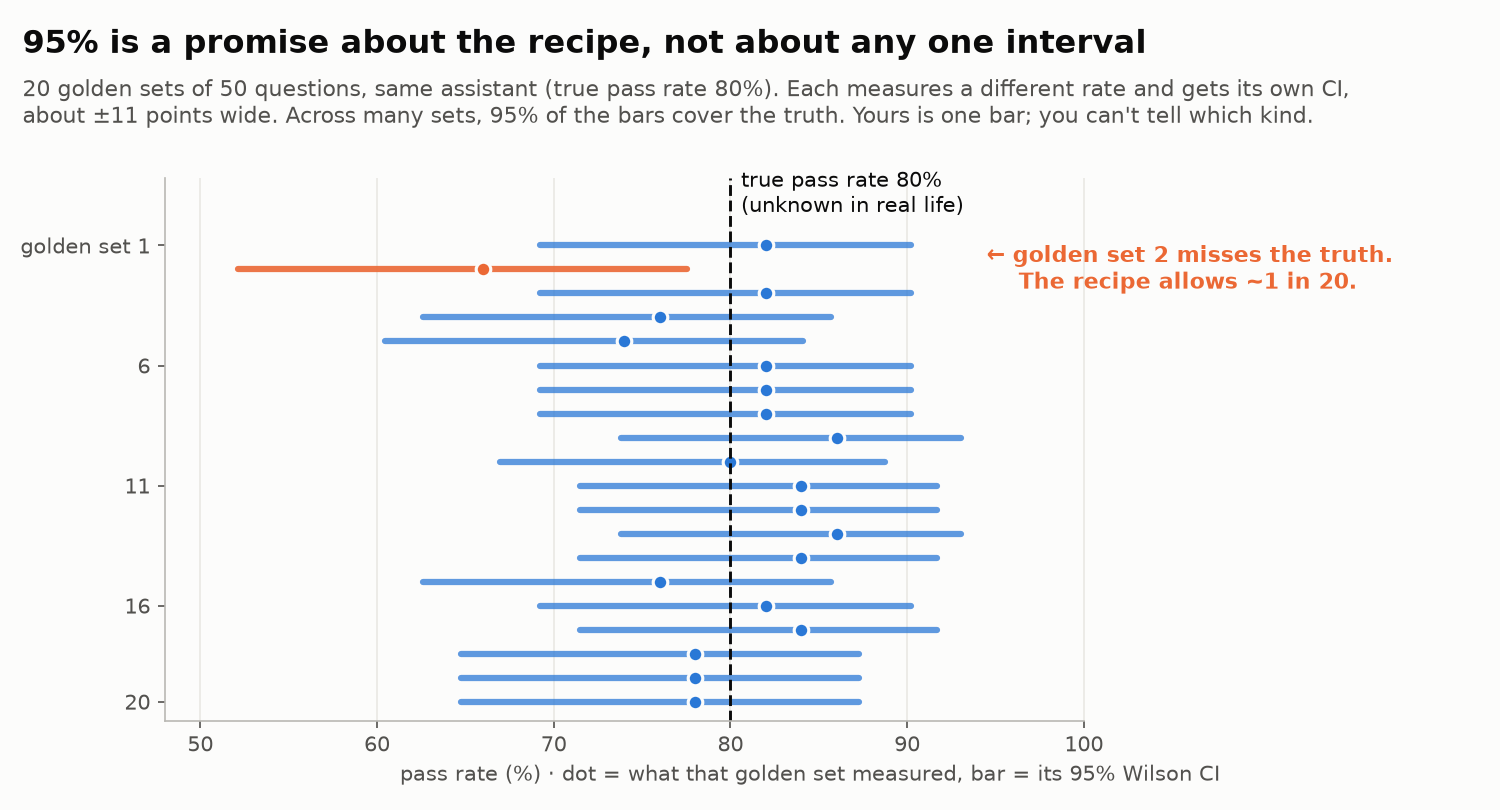

<sub>🖼️ *Twenty golden sets, twenty intervals, one miss.*</sub>

✋ **Your turn:** the **standard error** (SE), the typical wobble of a pass rate between samples, is **√(p(1−p)/n)**. A 95% CI is about ± 2 SE.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_se = math.sqrt(r1 * (1 - r1) / n)

In [ ]:
# ✋ Your turn: v1 passed r1 = 78% of n = 50 golden questions.
my_se = ...   # ✏️ the standard error of r1, as a fraction (math.sqrt is available)

check("SE of a 50-case pass rate", my_se, _ref_se,
      hint="Plug p = r1 and n into √(p(1 − p) / n).",
      success=f"{_ref_se:.3f}, so the 95% CI is about ±{196 * _ref_se:.0f} points. On 50 cases, 78% means 'somewhere from the mid-60s to the high-80s'.")

▶️ **Run:** Wilson CIs for both versions → note the overlap and the perfect 50/50.

In [ ]:
def wilson_ci(k, n, z=1.96):
    """95% Wilson score interval for k passes out of n."""
    p = k / n
    center = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return max(0.0, center - half), min(1.0, center + half)


ci1, ci2 = wilson_ci(k1, n), wilson_ci(k2, n)
print(f"v1: {pct(r1)}   95% CI {pct(ci1[0], 1)} to {pct(ci1[1], 1)}")
print(f"v2: {pct(r2)}   95% CI {pct(ci2[0], 1)} to {pct(ci2[1], 1)}")
print(f"The two intervals overlap by {100 * (ci1[1] - ci2[0]):.1f} points.")
lo_p, hi_p = wilson_ci(50, 50)
print(f"A perfect 50/50: textbook CI 100.0% to 100.0%; Wilson {pct(lo_p, 1)} to {pct(hi_p, 1)}")

In [ ]:
# @title 🔮 Predict: if v2 were EXACTLY as good as v1, how often would a fresh 50-case golden set still show v2 winning by 6+ points?
fake_win_share_will_be = "— pick one —"  # @param ["— pick one —", "A) about 50%", "B) under 1%", "C) about 5%", "D) about 25%"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** 5,000 golden sets in that do-nothing world → read the orange tail.

In [ ]:
sims = draw_golden_sets(n_sets=5000, null=True)        # a world where v2 is EXACTLY as good as v1
null_gap = (sims.v2_rate - sims.v1_rate).round(2)
# 👀 Look at: the share of do-nothing worlds in which v2 still "wins" by at least the PM's +6
p_fake_win = (null_gap >= round(gain, 2)).mean()
p_any_gap = (null_gap.abs() >= round(gain, 2)).mean()   # a gap that big in either direction
v1_lo, v1_hi = np.percentile(sims.v1_rate, [2.5, 97.5])

plot_null_gaps(null_gap, gain, title=f"v2 no better, yet {pct(p_fake_win)} of golden sets show a ≥{100 * gain:.0f}-pt 'win'")

insight(
    f"If v2 changed nothing, {pct(p_fake_win)} of 50-case golden sets would still show it winning by {100 * gain:.0f}+ points",
    f"A gap of {100 * gain:.0f}+ points in *either* direction shows up {pct(p_any_gap)} of the time. Even v1's own score "
    f"ranges from {pct(v1_lo)} to {pct(v1_hi)} (middle 95%) across golden sets, with the same prompt and the same model. "
    f"Rule of thumb: **on 50 cases a single pass rate is about ±{100 * (ci1[1] - ci1[0]) / 2:.0f} points; "
    "never report one without its interval.**",
    kind="surprise",
)
insight(
    "Report every eval score with a standard error (Miller, 2024)",
    "Anthropic's *Adding Error Bars to Evals* (Miller, arXiv 2411.00640, Nov 2024) recommends a standard error on every "
    "eval score, clustered SEs for grouped questions, resampling answers, paired comparisons, and power analysis: the "
    "rest of Part A. A 50-item eval at 80% accuracy has SE ≈ 5.7 points, a 95% CI of about ±11 points; "
    "100 items still gives about ±7.8.",
    kind="research",
)

quiz("Your prediction: fake 6-point wins", fake_win_share_will_be,
     correct=min({"A": 0.5, "B": 0.005, "C": 0.05, "D": 0.25}.items(), key=lambda kv: abs(math.log(kv[1] / p_fake_win)))[0],
     why=f"{pct(p_fake_win)} of do-nothing golden sets show v2 ahead by 6+ points: about one in four.")

🔍 **What just happened:** with no real difference, two 50-case scores differ by about 7 points (SD). +6 is an ordinary draw.

🗣️ **Say it to a colleague:** "On 50 cases, a 6-point gap is what *no change* looks like a quarter of the time."

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

v1 **64.8–87.2%**, v2 **71.5–91.7%**; perfect 50/50: Wilson **92.9–100%**. Chart: **"v2 no better, yet 24% of golden sets show a ≥6-pt 'win'"**.
</details>

In [ ]:
# @title ❓ Quick check: v1 is 78% (CI 65–87%) and v2 84% (CI 72–92%). The intervals overlap. What follows?
answer = "— pick one —"  # @param ["— pick one —", "A) v2 is not better than v1", "B) Nothing yet: overlap is not a test; compare the per-question differences", "C) v2 is better, because 84 is above 78", "D) Use p ± 1.96·SE instead: Wilson is too wide"]
quiz('Overlapping intervals', answer, correct="B",
     why='Two CIs can overlap while the difference is real. The right test works on paired differences: Task 3.',
     wrong={"A": 'Overlap does not prove equality; the difference needs its own interval.',
          "C": 'That ignores the ±11-point noise you just measured.',
          "D": "The textbook interval calls a perfect 50/50 '100% to 100%'. Wilson is the honest one."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>A pass rate without an interval is a rumor: on 50 cases, ±11 points is normal.</b></font>

</td></tr></table>

---

## Task 3: Compare the Same Questions (Paired Analysis)

<big><b>Both versions answered the same 50 questions. Use that.</b></big>

> 🎯 **Goal:** measure the gain from <b>per-question differences</b>.<br>
> ❓ **The question:** does pairing make the +6 significant?<br>
> 👀 **Watch for:** how few questions carry the evidence.

> 📘 **Concept · Paired comparison (discordant pairs)**
>
> **What it is:** score both versions on the same questions and analyze each question's difference, d = v2 − v1. The questions where d ≠ 0, the **discordant pairs** ("fixed": v1 FAIL → v2 PASS; "broke": v1 PASS → v2 FAIL), carry all the evidence about which version is better.
>
> **What it can't tell you:** whether a flip is a real change or a re-roll of a random answer (Task 5), or whether the questions are independent (Task 4).
>
> **Anchor:** the PM's +6 is 5 fixed minus 2 broke; the other 43 questions cancel out.

<!-- img: discordant-pairs.png -->
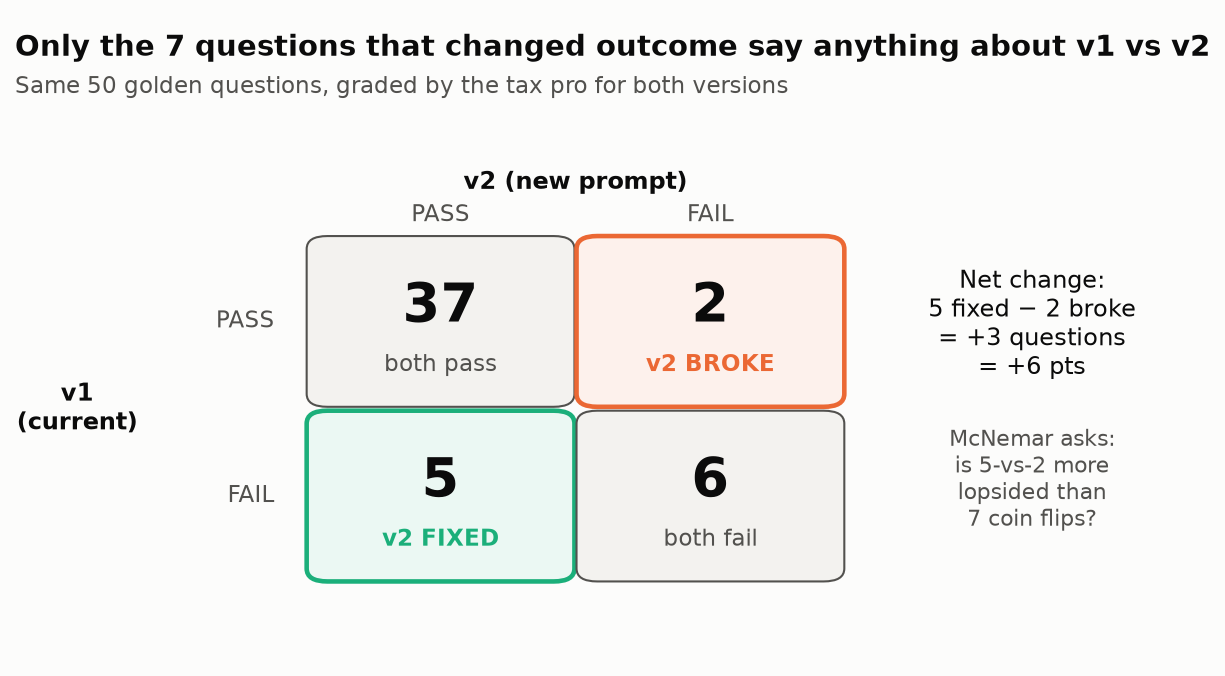

<sub>🖼️ *Only the 7 discordant questions say anything about v1 vs v2.*</sub>

▶️ **Run:** fixed vs broke, then the **McNemar test** (each changed question is a coin flip if v2 is no better) → read the p-value.

In [ ]:
def mcnemar_exact_p(fixed, broke):
    """Exact two-sided McNemar test: if v2 were no better, each changed question is a fair coin flip."""
    m = fixed + broke                     # 👀 Look at: only the changed questions enter the test; the 43 ties never do
    return 1.0 if m == 0 else float(min(1.0, 2 * stats.binom.cdf(min(fixed, broke), m, 0.5)))


fixed = int(((golden.v1_pass == 0) & (golden.v2_pass == 1)).sum())
broke = int(((golden.v1_pass == 1) & (golden.v2_pass == 0)).sum())
p_mcnemar = mcnemar_exact_p(fixed, broke)
corr = np.corrcoef(golden.v1_pass, golden.v2_pass)[0, 1]

tiles([
    ("v2 fixed", fixed, "v1 FAIL → v2 PASS", None),
    ("v2 broke", broke, "v1 PASS → v2 FAIL", None),
    ("McNemar p-value", f"{p_mcnemar:.2f}", "≥ 0.05: could easily be chance", "warning" if p_mcnemar >= 0.05 else "good"),
    ("v1/v2 outcome correlation", f"{corr:.2f}", "hard questions are hard for both", None),
])

<!-- img: p-value-coin-flips.png -->
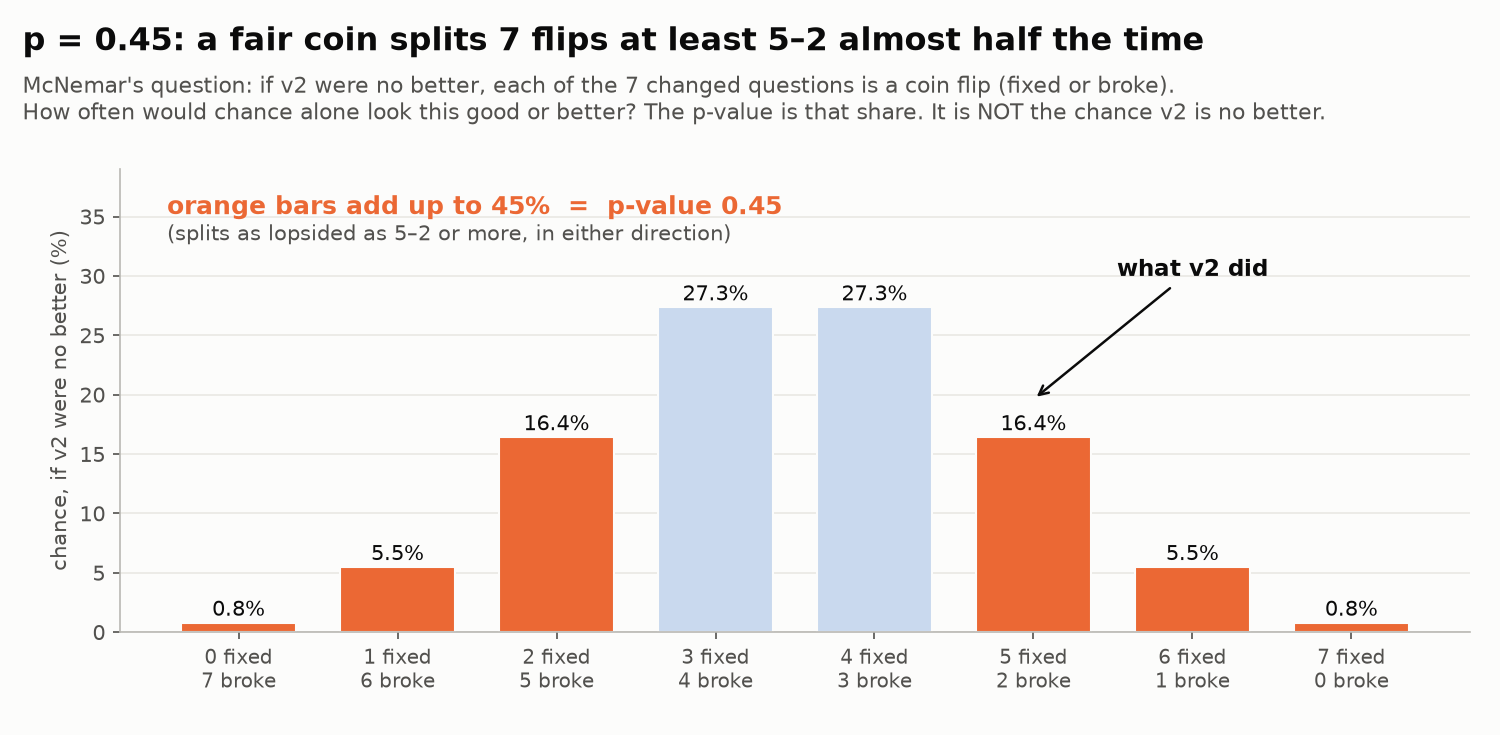

<sub>🖼️ *The p-value, drawn: 45% of fair-coin worlds look at least as lopsided as 5–2.*</sub>

In [ ]:
# @title 🔮 Predict: what does pairing do to the 95% CI on the +6?
pairing_ci_will_be = "— pick one —"  # @param ["— pick one —", "A) Narrower, and it excludes zero", "B) About the same", "C) Narrower, but zero is still inside", "D) Wider"]
print("🔮 Locked in. Graded after the reveal.")

✋ **Your turn:** the paired SE. `d` is +1 fixed, −1 broke, 0 tie.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_d_ref = (golden.v2_pass - golden.v1_pass).values.astype(float)
_ref_paired_se = _d_ref.std(ddof=1) / math.sqrt(len(_d_ref))
_ref_unpaired_se = math.sqrt(r1 * (1 - r1) / n + r2 * (1 - r2) / n)

In [ ]:
# ✋ Your turn: the standard error of the MEAN of d (the paired gain).
d = (golden.v2_pass - golden.v1_pass).values.astype(float)
print("d:", d.astype(int))

my_paired_se = ...   # ✏️ the sample SD of d, divided by √(number of questions)

check("Paired standard error", my_paired_se, _ref_paired_se,
      hint="SE of a mean = sample SD / √n. The sample SD divides by n − 1: d.std(ddof=1).",
      success=f"{_ref_paired_se:.3f}, vs {_ref_unpaired_se:.3f} for two separate rates: a third smaller, because the 43 tied questions add zero noise.")

▶️ **Run:** `paired_diff_ci()` (your formula inside) vs the unpaired CI → read the chart title.

In [ ]:
def paired_diff_ci(v1, v2, z=1.96):
    """Mean of (v2 − v1) over the SAME questions, with its SE and 95% CI."""
    d = np.asarray(v2, float) - np.asarray(v1, float)
    se = d.std(ddof=1) / math.sqrt(len(d))
    return {"diff": d.mean(), "se": se, "lo": d.mean() - z * se, "hi": d.mean() + z * se}


se_unpaired = math.sqrt(r1 * (1 - r1) / n + r2 * (1 - r2) / n)   # treats v1 and v2 as unrelated samples
unpaired = {"diff": gain, "se": se_unpaired, "lo": gain - 1.96 * se_unpaired, "hi": gain + 1.96 * se_unpaired}
paired = paired_diff_ci(golden.v1_pass, golden.v2_pass)          # 👀 Look at: one difference per question
shrink = 1 - paired["se"] / unpaired["se"]
data_equiv = (unpaired["se"] / paired["se"]) ** 2

plot_gain_cis([("Unpaired (two separate rates)", unpaired, PALETTE[6]),
               ("Paired (per-question differences)", paired, PALETTE[0])],
              title=f"Pairing shrinks the error bar by {shrink:.0%}, but zero is still inside")

insight(
    f"v2 fixed {fixed} questions and broke {broke}: the +{100 * gain:.0f} rests on {fixed + broke} coin flips "
    f"(McNemar p = {p_mcnemar:.2f})",
    f"Pairing cut the standard error by {shrink:.0%}: v1 and v2 outcomes correlate at r = {corr:.2f} (hard questions "
    f"are hard for both), and pairing cancels that shared difficulty, worth **{data_equiv:.1f}× more questions** for "
    f"free. Yet the paired 95% CI is still {100 * paired['lo']:+.1f} to {100 * paired['hi']:+.1f} points. "
    "Rule of thumb: **compare versions on the same questions and report the paired CI and the fixed/broke counts, "
    "never two separate pass rates.**",
)

quiz("Your prediction: what pairing does", pairing_ci_will_be,
     correct="A" if paired["lo"] > 0 else "C" if paired["se"] < 0.9 * unpaired["se"] else "B" if paired["se"] < 1.1 * unpaired["se"] else "D",
     why=f"Pairing cut the SE by {shrink:.0%}, yet the CI is still {100 * paired['lo']:+.1f} to {100 * paired['hi']:+.1f} points: zero is inside.")

🔍 **What just happened:** the 43 tied questions cancel, so the estimate rests on 7 flips, and 5–2 is an ordinary split for 7 fair coins.

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

Tiles **5** fixed, **2** broke, p **0.45**, r **0.56**. Unpaired CI **−9.3 to +21.3**; paired **−4.3 to +16.3** (SE **33%** smaller).
</details>

In [ ]:
# @title ❓ Quick check: McNemar gives p = 0.45 for 5 fixed vs 2 broke. What does 0.45 mean?
answer = "— pick one —"  # @param ["— pick one —", "A) There is a 45% chance that v2 is no better", "B) v2 is 55% likely to be better", "C) 45% of the questions changed outcome", "D) If v2 were no better, a split at least this lopsided would happen 45% of the time"]
quiz('Reading a p-value', answer, correct="D",
     why='A p-value is computed inside the no-difference world. 0.45 says 5–2 is an everyday result there.',
     wrong={"A": 'The classic misreading: a p-value is not the probability that the null is true.',
          "B": 'Same misreading, flipped.',
          "C": 'Only 7 of 50 changed (14%).'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Compare versions on the same questions: report fixed / broke and the paired CI.</b></font>

</td></tr></table>

---

## Task 4: Questions Come in Clusters

<big><b>Error bars from a handful of conversations are too narrow.</b></big>

> 🎯 **Goal:** re-compute the SE by conversation, and find which conversations drive the gain.<br>
> ❓ **The question:** how many independent questions are your 50 worth?<br>
> 👀 **Watch for:** one conversation carrying the whole win.

> 📘 **Concept · Effective n**
>
> **What it is:** how many *independent* questions a correlated test set is worth: n ÷ (clustered SE ÷ naive SE)².
>
> **What it can't tell you:** which clusters drive a result; for that, break the gain down by cluster (this task's bar chart).
>
> **Anchor:** the golden set is 10 conversations × 5 follow-ups. If the assistant misreads "S-corp owner, lives in NJ, works in NY" in turn 1, the five follow-ups tend to fail together: five rows, closer to one piece of evidence.

<!-- img: bootstrap-conversations.png -->
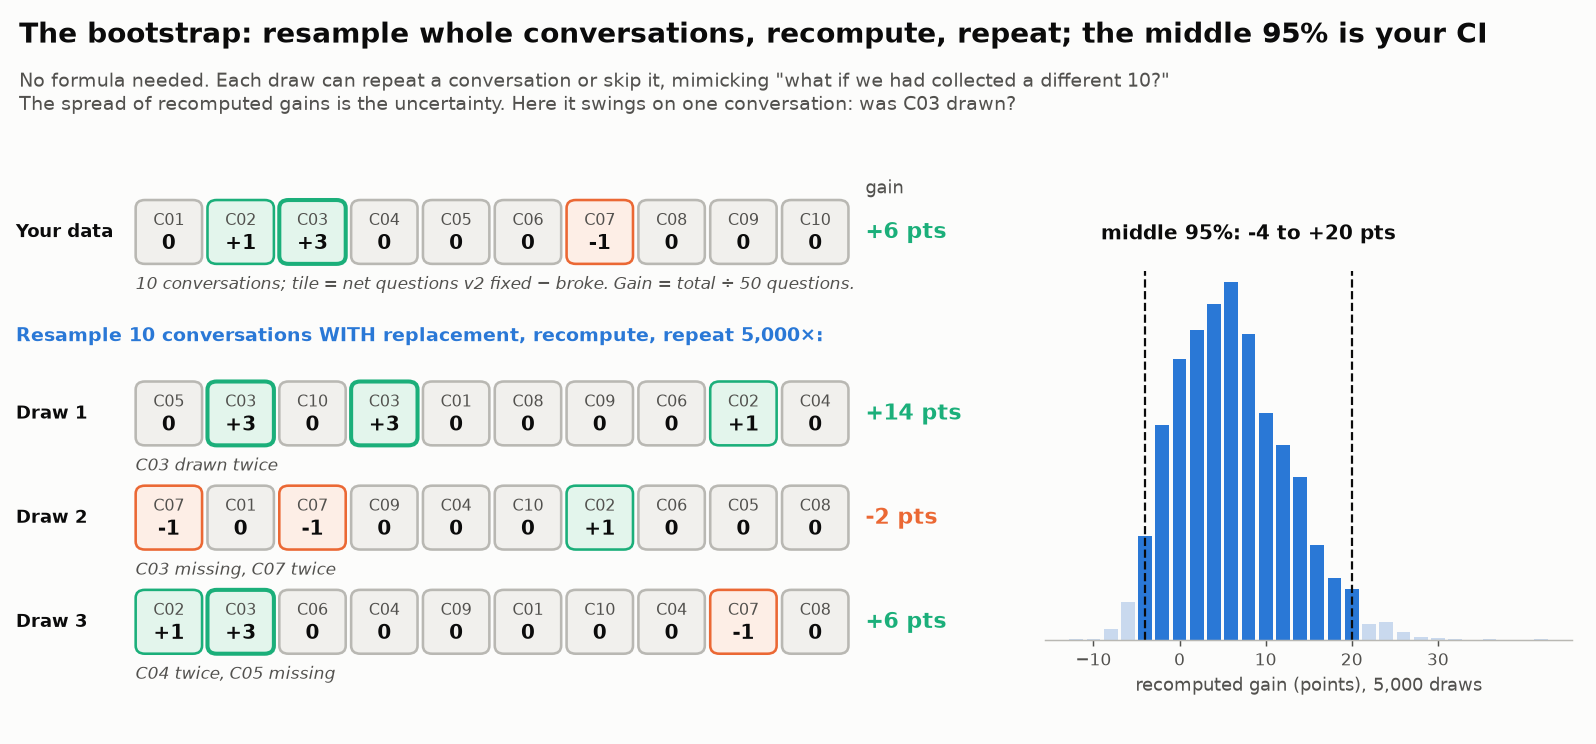

<sub>🖼️ *Whether C03 lands in a resample decides most of the answer.*</sub>

▶️ **Run:** a **clustered SE** sums each conversation's residuals *before* squaring → compare the two CIs.

In [ ]:
def clustered_se(x, clusters):
    """Clustered SE of a mean: sum residuals WITHIN each cluster first, then square. G/(G-1) corrects for few clusters."""
    x = np.asarray(x, float)
    # 👀 Look at: residuals are summed inside each conversation BEFORE squaring, so five correlated rows count once
    sums = pd.Series(x - x.mean()).groupby(np.asarray(clusters)).sum().values
    G = len(sums)
    return math.sqrt(G / (G - 1) * (sums**2).sum()) / len(x)


conv = golden.conversation
d = golden.v2_pass - golden.v1_pass
naive_v2 = golden.v2_pass.std(ddof=1) / math.sqrt(n)
clust_v2 = clustered_se(golden.v2_pass, conv)
ratio_v2 = clust_v2 / naive_v2
clust_d = clustered_se(d, conv)
paired_cl = {"diff": d.mean(), "se": clust_d, "lo": d.mean() - 1.96 * clust_d, "hi": d.mean() + 1.96 * clust_d}

print(f"v2 95% CI, naive (50 independent questions): ±{196 * naive_v2:.0f} pts")
print(f"v2 95% CI, clustered (10 conversations):     ±{196 * clust_v2:.0f} pts")

✋ **Your turn:** effective n = n ÷ (clustered SE ÷ naive SE)².

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_n_eff = n / (clust_v2 / naive_v2) ** 2

In [ ]:
# ✋ Your turn: how many INDEPENDENT questions are the 50 golden questions worth?
my_n_eff = ...   # ✏️ one expression using n, clust_v2 and naive_v2

check("Effective n of the golden set", my_n_eff, _ref_n_eff,
      hint="The clustered SE is (clust_v2 / naive_v2) times the naive one; n scales with 1 / SE².",
      success=f"≈ {_ref_n_eff:.0f}: fifty rows, about a dozen independent pieces of evidence.")

▶️ **Run:** the four tiles.

In [ ]:
n_eff = n / ratio_v2**2
tiles([
    ("v2 95% CI, naive", f"±{196 * naive_v2:.0f} pts", "treats 50 questions as independent", None),
    ("v2 95% CI, clustered", f"±{196 * clust_v2:.0f} pts", "10 conversations × 5 questions", "warning"),
    ("SE inflation", f"{ratio_v2:.1f}×", "clustered ÷ naive", "warning"),
    ("Effective n", f"≈ {n_eff:.0f}", f"of {n} questions", "serious"),
])

In [ ]:
# @title 🔮 Predict: what share of v2's net gain (+3 questions) comes from its single best conversation?
top_conversation_share_will_be = "— pick one —"  # @param ["— pick one —", "A) 100%", "B) about 30%", "C) about 10%", "D) about 60%"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** net questions fixed per conversation → read the chart title.

In [ ]:
by_conv = (golden.assign(net=d)
           .groupby(["conversation", "customer"], as_index=False)
           .agg(net_change=("net", "sum"), v2_fails=("v2_pass", lambda s: int((s == 0).sum()))))
top = by_conv.loc[by_conv.net_change.idxmax()]
share_top = top.net_change / d.sum()                  # 👀 Look at: one conversation's share of the whole net gain

plot_net_by_conversation(by_conv, title=f"{share_top:.0%} of v2's net gain comes from one conversation ({top.conversation})")

insight(
    f"Your {n} golden questions behave like about {n_eff:.0f} independent ones",
    f"Clustering by conversation makes v2's standard error {ratio_v2:.1f}× larger: its 95% CI is "
    f"±{196 * clust_v2:.0f} points, not ±{196 * naive_v2:.0f}. The paired gain's clustered CI widens to "
    f"{100 * paired_cl['lo']:+.1f} to {100 * paired_cl['hi']:+.1f} points. And {share_top:.0%} of the net gain comes from "
    f"the 5 questions of {top.conversation} (*{top.customer}*); every other conversation nets to zero. "
    "Rule of thumb: **when cases share a conversation, document or customer, cluster your SEs (or bootstrap whole "
    "clusters), and check which clusters drive a 'win'.**",
)
insight(
    "Naive standard errors can be 3× too small (Miller, 2024)",
    "On real benchmarks with grouped questions, Miller (arXiv 2411.00640) measured clustered/naive SE ratios of "
    "**3.05 on DROP**, 1.88 on MGSM and 1.10 on RACE-H. Golden sets built from conversations, multi-question documents "
    "or a handful of customers are clustered by construction.",
    kind="research",
)

quiz("Your prediction: one conversation's share", top_conversation_share_will_be,
     correct=min({"A": 1.0, "B": 0.3, "C": 0.1, "D": 0.6}.items(), key=lambda kv: abs(kv[1] - share_top))[0],
     why=f"{share_top:.0%}: {top.conversation} (*{top.customer}*) nets +{top.net_change}; the other nine net to zero.")

🔍 **What just happened:** C03's five correlated questions count as one piece of evidence, and carry the whole gain.

🗣️ **Say it to a colleague:** "We have 50 rows and about 12 data points. Count conversations, not questions."

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

Naive **±10**, clustered **±21** pts, **2.0×**, n_eff **≈ 12**. Chart: **"100% of v2's net gain comes from one conversation (C03)"**; clustered paired CI **−7.1 to +19.1**.
</details>

In [ ]:
# @title ❓ Quick check: next quarter's golden set has a budget of 50 questions. Which design gives the tighter error bar?
answer = "— pick one —"  # @param ["— pick one —", "A) 50 questions from 50 different conversations", "B) 50 questions from 10 conversations, 5 each", "C) Same either way: both have n = 50"]
quiz('Clustered design', answer, correct="A",
     why='Questions inside one conversation fail together. Spread the budget across clusters.',
     wrong={"B": "That is today's design: effective n ≈ 12.",
          "C": 'n counts rows; the SE counts independent evidence.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Count conversations, not rows: cluster the SE when cases share a conversation or customer.</b></font>

</td></tr></table>

---

## Task 5: Same Prompt, Same Questions, Different Answers

<big><b>Re-running until the number looks good ships a dice roll.</b></big>

> 🎯 **Goal:** re-run both versions 10 times on the same questions.<br>
> ❓ **The question:** did v2 learn something in C03, or was v1 unlucky that day?<br>
> 👀 **Watch for:** v2 losing to v1 on re-runs of the same prompts.

> 💡 **Key idea:** each golden result is **one draw per question**; temperature 0 doesn't fix that on hosted APIs. Ask K times, average per question, and still count N questions, never K × N.

In [ ]:
# @title 🔮 Predict: re-run the SAME v2 ten times on the same 50 questions. How far apart are its best and worst pass rates?
rerun_swing_will_be = "— pick one —"  # @param ["— pick one —", "A) 0 points", "B) 16 points", "C) 4 points", "D) 8 points"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** 10 re-runs per version → read the chart title.

In [ ]:
K = 10
R1, R2 = rerun_golden("v1", k=K), rerun_golden("v2", k=K)      # shape: (10 runs, 50 questions), 1 = PASS
runs = pd.DataFrame({"v1": R1.mean(axis=1), "v2": R2.mean(axis=1)})
swing_v2 = runs.v2.max() - runs.v2.min()                        # 👀 Look at: same prompt, same questions, same grader
flipped_v2 = int((R2.min(axis=0) != R2.max(axis=0)).sum())     # questions that both passed AND failed across runs
v2_lost = int((runs.v2 < runs.v1).sum())
rerun_gain = R2.mean() - R1.mean()

plot_reruns(runs, {"v1": r1, "v2": r2}, title=f"Re-running the same v2 moves its score by {100 * swing_v2:.0f} points")
print(runs.T.map(lambda x: f"{100 * x:.0f}%").to_string())

quiz("Your prediction: the re-run swing", rerun_swing_will_be,
     correct=min({"A": 0, "B": 16, "C": 4, "D": 8}.items(), key=lambda kv: abs(kv[1] - 100 * swing_v2))[0],
     why=f"{100 * swing_v2:.0f} points ({pct(runs.v2.min())} to {pct(runs.v2.max())}): same prompt, questions and grader.")

✋ **Your turn:** C03 gave v2 three golden-set "fixes". Check them on the re-runs.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_in_top = (golden.conversation == top.conversation).values
_ref_c03_gap = 100 * (R2[:, _in_top].mean() - R1[:, _in_top].mean())

In [ ]:
# ✋ Your turn: R1, R2 are (10 runs × 50 questions) arrays of 0/1. in_top masks C03's 5 questions.
in_top = (golden.conversation == top.conversation).values

my_c03_gap = ...   # ✏️ in points: v2's re-run pass rate on C03 minus v1's

check("C03's gain on the re-runs", my_c03_gap, _ref_c03_gap,
      hint="R2[:, in_top].mean() is v2's pass rate on C03 across all 10 runs. Subtract v1's, then × 100.",
      success=f"{_ref_c03_gap:+.0f} points, not the golden run's +60: v1 passes C03 {R1[:, in_top].mean():.0%} of the time, v2 {R2[:, in_top].mean():.0%}. The 'fix' was v1 rolling low once.")

▶️ **Run:** the cards.

In [ ]:
in_top = (golden.conversation == top.conversation).values
top_v1, top_v2 = R1[:, in_top].mean(), R2[:, in_top].mean()   # 👀 Look at: C03's five questions, 10 re-runs per version

insight(
    f"{top.conversation}'s 'fix' was luck: across 10 re-runs v1 passes those questions {top_v1:.0%} of the time, "
    f"v2 {top_v2:.0%}",
    f"Same prompt, same questions, same grader: v2 scored between {pct(runs.v2.min())} and {pct(runs.v2.max())}, "
    f"{flipped_v2} of {n} questions flipped between PASS and FAIL at least once, and v2 *lost* to v1 in {v2_lost} of "
    f"{K} paired re-runs. Averaged over all re-runs the gain is {100 * rerun_gain:+.1f} points, not +{100 * gain:.0f}. "
    "Rule of thumb: **one answer per question is one roll of the dice; average several answers per question before "
    "you compare versions.**",
    kind="surprise",
)
insight(
    "Temperature 0 is not deterministic (Thinking Machines, 2025)",
    "In *Defeating Nondeterminism in LLM Inference* (Sep 2025), 1,000 identical temperature-0 requests produced "
    "**80 distinct completions**; they diverged at token 103. The root cause is that server batch size varies with load. "
    "Miller (2024) adds: in his worked example, resampling K answers per question cuts the score's variance by 1/3 "
    "at K=2 and 1/2 at K=4 (never more than 2/3), and pooling K×N answers as if independent is invalid.",
    kind="research",
)

<!-- img: comic-v2-vs-v2.png -->
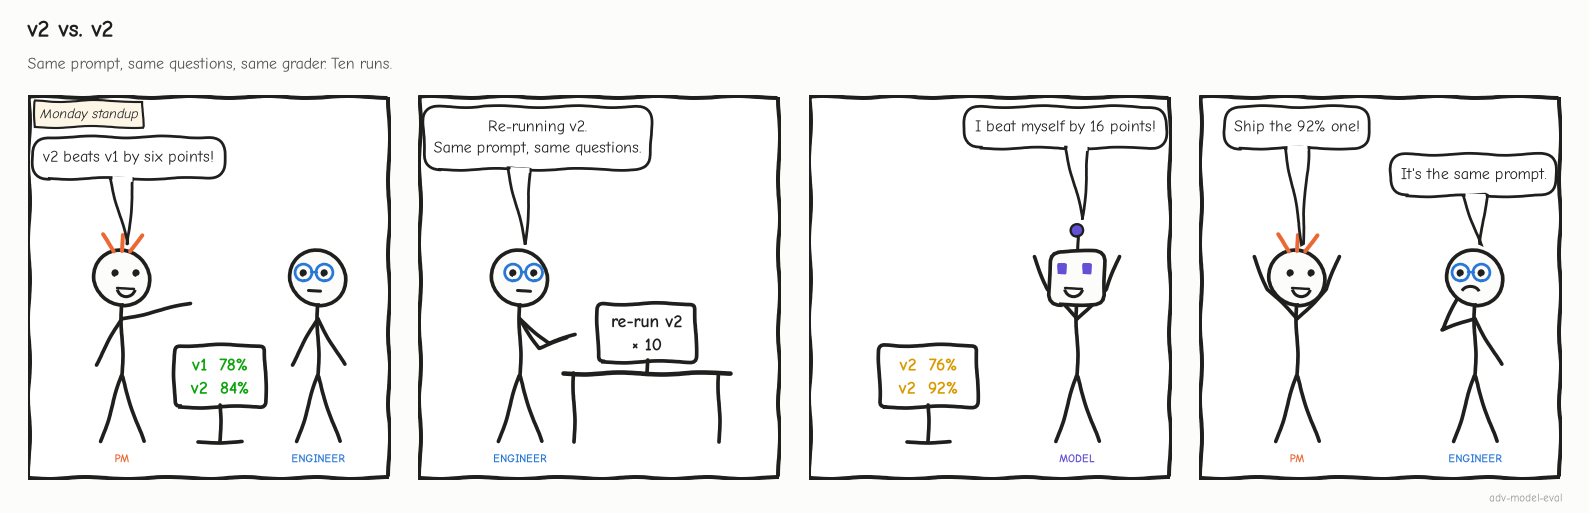

🎛️ **Experiment:** drag `SEED` and run. Does any seed give the identical v2 a narrow spread?

In [ ]:
# 🎛️ Ten more re-runs of the IDENTICAL v2 prompt from another random seed. SEED = 0 is the run above.
SEED = 0  # @param {type:"slider", min:0, max:20, step:1}

again = rerun_golden("v2", k=K, seed=SEED).mean(axis=1)
print(f"seed {SEED}: v2 scored {pct(again.min())} to {pct(again.max())} "
      f"(swing {100 * (again.max() - again.min()):.0f} pts, mean {pct(again.mean(), 1)})")

🔍 **What just happened:** 28 of 50 questions re-roll between PASS and FAIL. Averaged over all runs, v2's gain is −0.8 points.

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

Chart: **"Re-running the same v2 moves its score by 16 points"** (76–92%); **28** flipped; v2 lost **6** of 10; C03 v1 **82%**, v2 **84%**. Seed 1: 74–86%.
</details>

In [ ]:
# @title ❓ Quick check: ten re-runs of v2 scored between 76% and 92%. What goes in the launch doc?
answer = "— pick one —"  # @param ["— pick one —", "A) 92%: the best run shows what v2 can do", "B) 84%: the official golden-set run", "C) The pass rate over all 500 answers, with n = 500 in the CI", "D) The mean over runs, analyzed as 50 per-question averages"]
quiz('Reporting a nondeterministic score', answer, correct="D",
     why='Average the K answers per question, then analyze N = 50 questions.',
     wrong={"A": 'Picking the best of 10 runs is cherry-picking a dice roll (see the comic).',
          "B": 'One run is one draw anywhere in the 76–92% spread.',
          "C": 'Ten answers to one question are not ten independent cases.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>One answer per question is one roll of the dice: average K answers, and still count N.</b></font>

</td></tr></table>

---

## Task 6: How Many Test Cases Do You Actually Need?

<big><b>A golden set nobody sized can't see the changes the team argues about.</b></big>

> 🎯 **Goal:** code the power formula, then size the next eval with Task 5's variance.<br>
> ❓ **The question:** how many questions does a 3-point gain need?<br>
> 👀 **Watch for:** what averaging K answers buys, and what it can't.

> 📘 **Concept · Power and minimum detectable effect (MDE)**
>
> **What it is:** **power** is the chance an eval detects a real change of size δ (by convention 80%, with a 5% false-alarm rate α); the **MDE** is the smallest change an eval of *n* questions detects with that power.
>
> **What it can't tell you:** that a change is absent. "No significant difference" from an eval whose MDE is bigger than the change you care about is silence, not evidence.
>
> **Anchor:** at 50 paired questions the MDE is about 18 points (left panel of the picture below), so the PM's golden set could never have confirmed, or ruled out, a 6-point gain.

> 📐 **Paired formula (Miller, 2024):** **n = (z<sub>α/2</sub> + z<sub>β</sub>)² · Var(d) / δ²**: z<sub>α/2</sub> = 1.96 (5% false alarms), z<sub>β</sub> = 0.84 (80% power), δ = the change to detect.

<details><summary>📐 Where Var(d) comes from</summary>

Var(d) = ω² + (σ²<sub>v1</sub> + σ²<sub>v2</sub>) / K. **σ²**: answer randomness within a question (K answers shrink it). **ω²**: real gain differences between questions (K can't).
</details>

<!-- img: power-mde.png -->
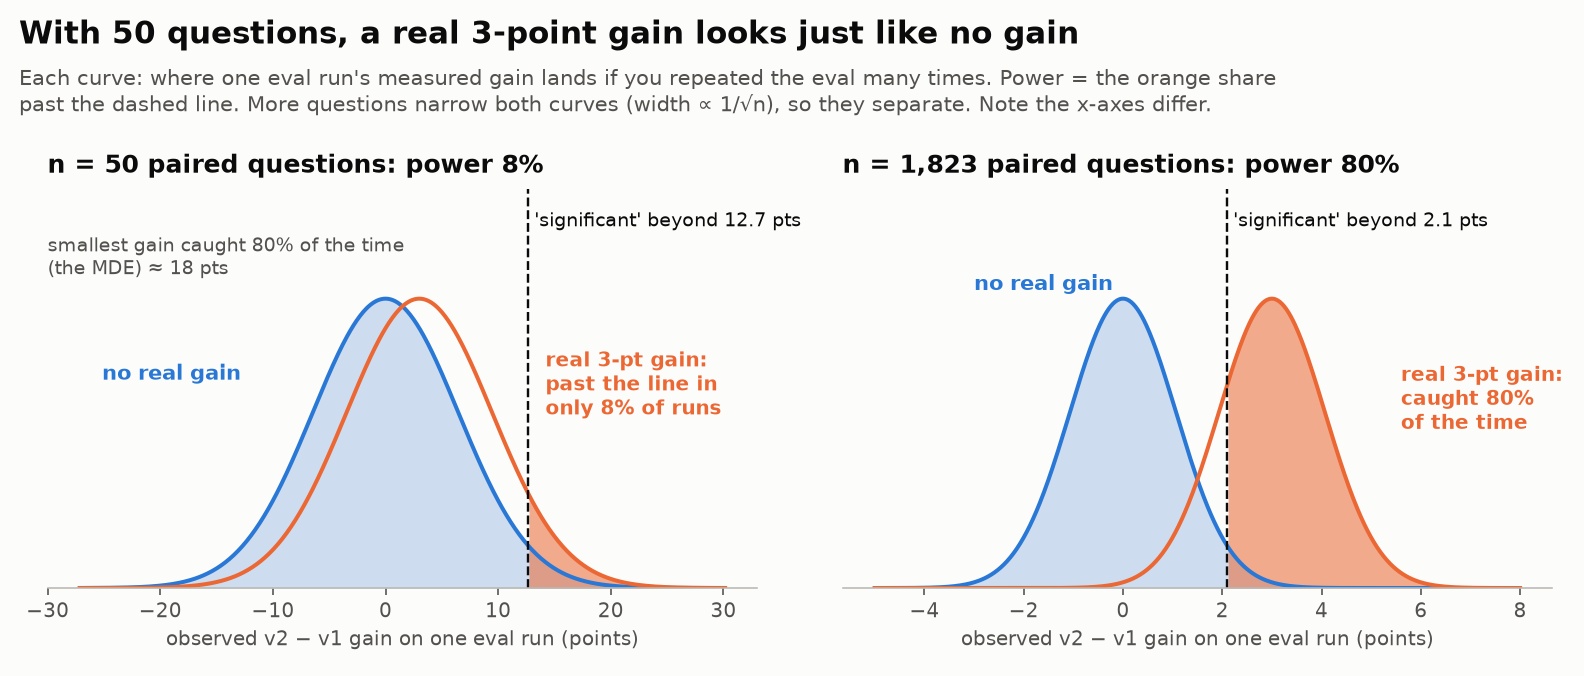

In [ ]:
# @title 🔮 Predict: how many paired questions does a real 3-point gain need (80% power)?
questions_for_3pts_will_be = "— pick one —"  # @param ["— pick one —", "A) about 300", "B) about 100", "C) about 1,800", "D) about 600"]
print("🔮 Locked in. Graded after the reveal.")

✋ **Your turn:** code the formula on Miller's published example.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_n_miller = _reference_cases_needed(0.03, 1 / 9)

In [ ]:
# ✋ Your turn: Miller's worked example: detect δ = 3 points when Var(d) = 1/9.
z_a, z_b = stats.norm.ppf(0.975), stats.norm.ppf(0.80)    # 1.96 and 0.84
delta, var_d = 0.03, 1 / 9

my_n = ...   # ✏️ questions needed, rounded UP to a whole number (math.ceil)

check("Miller's sample size", my_n, _ref_n_miller,
      hint="n = (z_a + z_b)² · var_d / delta², then math.ceil(...).",
      success=f"{_ref_n_miller}: about 1,000 questions to see 3 points, which is why new evals should start near 1,000.")

▶️ **Run:** `cases_needed()`, the variance pieces from Task 5's re-runs, and the plan → read *n for 3 pts*.

In [ ]:
def cases_needed(delta, var_per_question, alpha=0.05, power=0.80):
    """Smallest number of questions that detects a true change of `delta` (0.03 = 3 points)."""
    z_sum = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)
    return math.ceil(z_sum ** 2 * var_per_question / delta ** 2)


# Variance pieces, estimated from Task 5's re-runs (10 answers per question per version)
s2_v1 = R1.var(axis=0, ddof=1).mean()             # within-question answer randomness, v1
s2_v2 = R2.var(axis=0, ddof=1).mean()             # ... and v2
omega2 = max(0.0, np.var(R2.mean(axis=0) - R1.mean(axis=0), ddof=1) - (s2_v1 + s2_v2) / K)   # between-question

designs = {
    "Unpaired (separate question sets)": r1 * (1 - r1) + r2 * (1 - r2),
    "Paired, 1 answer per question": omega2 + s2_v1 + s2_v2,
    "Paired, 5 answers per question": omega2 + (s2_v1 + s2_v2) / 5,    # 👀 Look at: K answers shrink σ², never ω²
}
z_sum = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
plan = pd.DataFrame([
    {"design": name, "Var(d)": round(v, 3),
     **{f"n for {int(100 * dl)} pts": cases_needed(dl, v) for dl in (0.03, 0.05, 0.10)},
     "smallest change n=50 can detect": f"{100 * z_sum * math.sqrt(v / n):.0f} pts"}
    for name, v in designs.items()
])
display(plan)

▶️ **Run:** the sample-size curves.

In [ ]:
n_unp3, n_p3, n_k3 = plan["n for 3 pts"]
mde_p1 = 100 * z_sum * math.sqrt(designs["Paired, 1 answer per question"] / n)

plot_power_curves(designs, n, title=f"Your {n} cases can only detect changes of about {mde_p1:.0f} points or more")

insight(
    f"Detecting a 3-point gain takes {n_p3:,} paired questions: {n_p3 / n:.0f}× your golden set",
    f"Unpaired, it's {n_unp3:,} questions *per version*. Your {n}-case set can only detect changes of about "
    f"{mde_p1:.0f} points, so it could never have confirmed (or ruled out) a 6-point gain. Averaging 5 answers per "
    f"question cuts the requirement to {n_k3:,} questions, because here most of the variance is answer randomness "
    f"(σ² ≈ {s2_v1:.2f} per version) rather than real per-question differences (ω² ≈ {omega2:.3f}). "
    "Rule of thumb: **run the power calculation before you build the golden set, and size it for the smallest change "
    "you would act on.**",
)
insight(
    "About 1,000 questions to see 3 points (Miller, 2024)",
    "Miller's worked example: detecting δ = 3 points at α = 0.05 with 80% power (ω² = 1/9) needs about **969 "
    "questions**, so new evals should have at least about 1,000. Resampling helps small evals: with n = 198, raising K "
    "from 1 to 10 answers per question cut the minimum detectable effect from 13.2% to 7.5%.",
    kind="research",
)

quiz("Your prediction: questions for 3 points", questions_for_3pts_will_be,
     correct=min({"A": 300, "B": 100, "C": 1800, "D": 600}.items(), key=lambda kv: abs(math.log(kv[1] / n_p3)))[0],
     why=f"{n_p3:,} paired questions, {n_p3 / n:.0f}× the golden set. Five answers per question cut it to {n_k3:,}.")

🔍 **What just happened:** n grows with 1/δ², so halving δ quadruples n. K = 5 cut Var(d) from 0.21 to 0.05: most variance here is answer randomness.

🎛️ **Experiment:** drag `DELTA_PTS` to 1.5, then `K_ANSWERS` to 10. Where is the floor?

In [ ]:
# 🎛️ The planner. Defaults reproduce the table: δ = 3 points, K = 5 answers per question.
DELTA_PTS = 3  # @param {type:"slider", min:1, max:20, step:0.5}
K_ANSWERS = 5  # @param {type:"slider", min:1, max:10, step:1}

dl = DELTA_PTS / 100
print(f"To detect {DELTA_PTS} pts with 80% power:")
print(f"  paired, 1 answer per question     {cases_needed(dl, omega2 + s2_v1 + s2_v2):>7,} questions")
print(f"  paired, {K_ANSWERS:>2} answers per question   {cases_needed(dl, omega2 + (s2_v1 + s2_v2) / K_ANSWERS):>7,} questions")
print(f"  the ω² floor (K → ∞)              {cases_needed(dl, omega2):>7,} questions")

✋ **Your turn:** Brightbook can afford **600** graded questions. Find K with the planner.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_K = next(k for k in range(1, 50) if cases_needed(0.03, omega2 + (s2_v1 + s2_v2) / k) < 600)

In [ ]:
# ✋ Your turn: the smallest K (answers per question) that detects a 3-point gain with UNDER 600 questions.
my_K = ...   # ✏️ a whole number

check("Answers per question for a 600-question budget", my_K, _ref_K,
      hint="Keep DELTA_PTS at 3 and drag K_ANSWERS until the 'K answers' row drops below 600.",
      success=f"K = {_ref_K}: {cases_needed(0.03, omega2 + (s2_v1 + s2_v2) / _ref_K)} questions × {_ref_K} answers. Resampling shrinks the golden set, never below the ω² floor ({cases_needed(0.03, omega2)}).")

<details><summary>📋 <b>Checkpoint</b>: expected output</summary>

`cases_needed(0.03, 1/9)` = **969**.

| design | n for 3 pts | n for 10 pts | n=50 detects |
|---|---|---|---|
| Unpaired | 2669 | 241 | 22 pts |
| Paired, 1 answer | 1823 | 164 | 18 pts |
| Paired, 5 answers | 437 | 40 | 9 pts |

Planner at 1.5 pts: **7,289**.
</details>

🗣️ **Say it to a colleague:** "Our golden set sees 18-point changes. We're arguing about 6."

In [ ]:
# @title ❓ Quick check: your 50-case eval says 'no significant difference' between v1 and v2. What did you learn?
answer = "— pick one —"  # @param ["— pick one —", "A) v1 and v2 are equivalent", "B) Little: its MDE is about 18 points, so smaller changes are invisible to it", "C) v2 is slightly worse", "D) The test was run wrong; real differences are always significant"]
quiz('No significant difference', answer, correct="B",
     why='An eval whose MDE exceeds the change you care about is silent, not evidence.',
     wrong={"A": 'Absence of evidence from an underpowered eval is not evidence of absence.',
          "C": 'Non-significance says nothing about direction.',
          "D": 'At n = 50, real 6-point changes go undetected most of the time.'})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Size the eval before you build it: halving the change you want to see costs 4× the questions.</b></font>

</td></tr></table>

---

## 🔑 Part 1 in three lines

1. **+6 on 50 cases is 3 questions**: ±11 points of noise, 7 coin flips once paired.
2. **The 50 questions are worth about 12**, and the same prompt swings 16 points.
3. **3 points needs ~1,800 paired questions** (437 with 5 answers each).

▶️ **Run:** your Part 1 score, and what to revisit.

In [ ]:
scoreboard()

<center><font size="5"><b>➡️ Continue in Part 2: can you trust the judge's 90%?</b></font></center>

<center>

[![Open Part 2 In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/05b-statistical-rigor-judge-calibration-part-2-lab.ipynb)

</center>